# H09. 불안정 사이클이 특정 부품 상태에 몰려 있는가

| 항목 | 내용 |
|---|---|
| 질문 | 장치가 아직 안정되지 않은 사이클(안정 플래그 1)이 특정 상태에 몰려 있을까? |
| 귀무가설 H0 | 안정 플래그는 부품 상태와 독립이다 |
| 대립가설 H1 | 안정 플래그는 부품 상태와 관련 있다 |
| 검정 | 카이제곱 독립성 검정 (부품 4개 → Holm), 효과 크기 Cramér's V |
| 출처 (EDA) | F07 안정 플래그별 분포, F03 라벨 타임라인 |
| 데이터 | stable_flag × 부품 상태 4개 |
| 왜 중요한가 | 불안정 사이클을 학습에서 빼도 되는지 (편향 여부) |

**진행 순서:** 1 EDA 시각화 → 2 기술통계 → 3 가정 확인 → 4 정상성 확인 → 5 가설검정(p-값) → 6 사후검정·효과 크기 → 7 블록 평균 재확인 → 8 최종 판정 → 9 해석과 결정

유의수준은 **α = 0.05**로 미리 정했습니다. 표본이 2,205개로 커서 작은 차이도 p < 0.05가 되므로, **결론은 효과 크기와 함께** 내립니다.

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. EDA 시각화

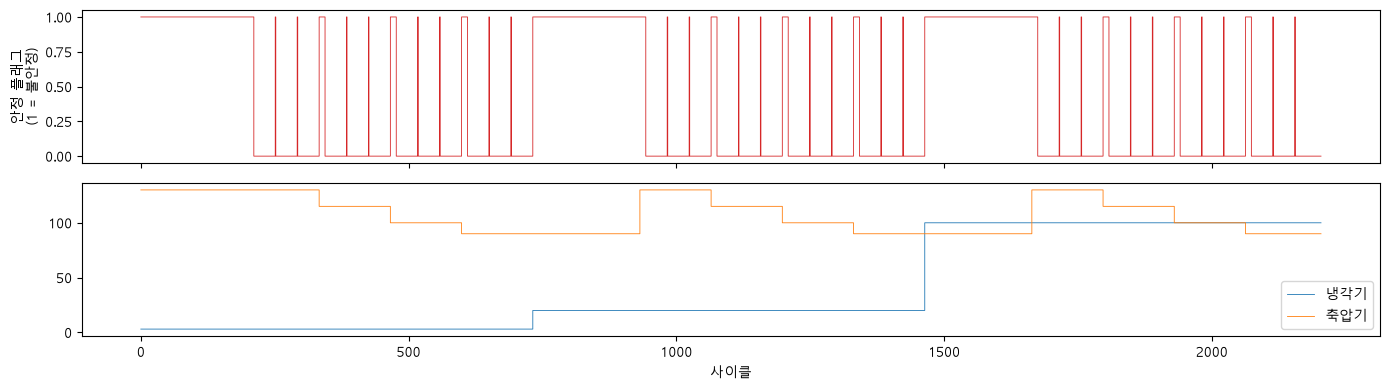

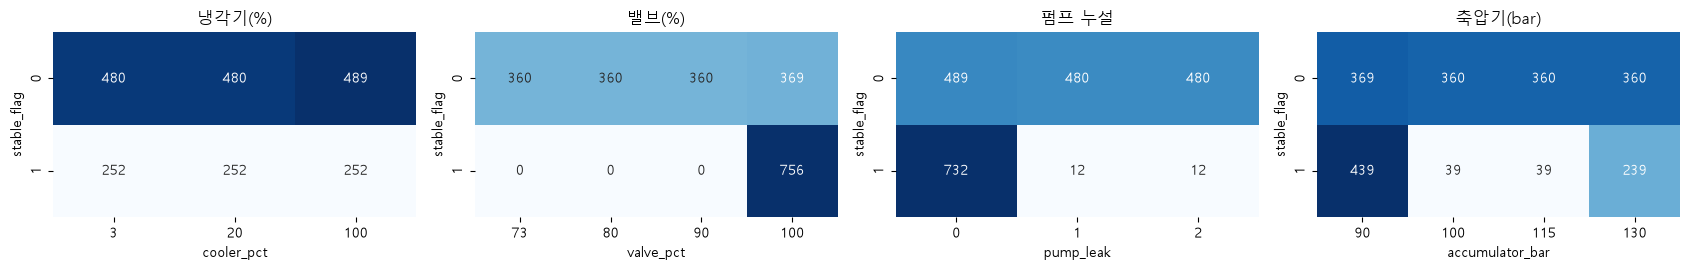

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(14, 4), sharex=True)
axes[0].step(cyc["cycle"], cyc["stable_flag"], where="post", lw=0.6, color="C3"); axes[0].set_ylabel("안정 플래그\n(1 = 불안정)")
axes[1].step(cyc["cycle"], cyc["cooler_pct"], where="post", lw=0.6, label="냉각기"); axes[1].step(cyc["cycle"], cyc["accumulator_bar"], where="post", lw=0.6, label="축압기")
axes[1].legend(); axes[1].set_xlabel("사이클"); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 4, figsize=(17, 2.8))
for ax, c in zip(axes, COMP):
    sns.heatmap(pd.crosstab(cyc["stable_flag"], cyc[c]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax); ax.set_title(COMP[c])
plt.tight_layout(); plt.show()

**EDA로 본 것:** 불안정 사이클은 냉각기나 축압기 상태가 **바뀐 직후**에 몰려 나타납니다. 교차표에서는 밸브 100%, 펌프 누설 0에 집중되어 보입니다.

## 2. 기술통계: 상태별 불안정 비율

In [3]:
for c in COMP: print(COMP[c], (cyc.groupby(c)["stable_flag"].mean()).round(2).to_dict())
u = cyc["stable_flag"] == 1; grp = (u != u.shift()).cumsum()[u]
lens = cyc[u].groupby(grp).size(); print(f"불안정 사이클 {u.sum()}개, 연속 구간 {len(lens)}개, 길이 분포: {lens.value_counts().sort_index().to_dict()}")

냉각기(%) {3: 0.34, 20: 0.34, 100: 0.34}
밸브(%) {73: 0.0, 80: 0.0, 90: 0.0, 100: 0.67}
펌프 누설 {0: 0.6, 1: 0.02, 2: 0.02}
축압기(bar) {90: 0.54, 100: 0.1, 115: 0.1, 130: 0.4}
불안정 사이클 756개, 연속 구간 36개, 길이 분포: {1: 24, 11: 9, 211: 3}


## 3. 가정 확인

카이제곱 검정은 **모든 칸의 기대빈도가 5 이상**이어야 합니다. 그렇지 않으면 Fisher 정확 검정을 씁니다.

In [4]:
for c in COMP: print(COMP[c], '최소 기대빈도 =', round(cramers_v(pd.crosstab(cyc['stable_flag'], cyc[c]))['min_expected'], 1))

냉각기(%) 최소 기대빈도 = 251.0
밸브(%) 최소 기대빈도 = 123.4
펌프 누설 최소 기대빈도 = 168.7
축압기(bar) 최소 기대빈도 = 136.8


## 4. 정상성 대신: 시간 배치 확인

안정 플래그와 부품 상태는 범주형이라 ADF·KPSS 대상이 아닙니다. 대신 불안정 사이클이 **시간상 어디에** 생기는지(상태 변경 직후인지) 확인합니다.

In [5]:
changed = (cyc[list(COMP)].diff().abs().sum(axis=1) > 0)
since = changed.cumsum(); dist = cyc.groupby(since).cumcount()          # 마지막 상태 변경 후 몇 사이클째인지
display(pd.crosstab(pd.cut(dist, [-1, 0, 10, 50, 250, 2205], labels=["변경 직후 0", "1~10", "11~50", "51~250", "250 이후"]), cyc["stable_flag"]))

stable_flag,0,1
row_0,,
변경 직후 0,144,50
1~10,1297,129
11~50,8,120
51~250,0,457


## 5. 가설검정 (p-값)

In [6]:
res = pd.DataFrame([dict(부품=COMP[c], **cramers_v(pd.crosstab(cyc["stable_flag"], cyc[c]))) for c in COMP])
res["p_holm"] = holm(res["p"]); res["효과"] = res["V"].map(lambda v: size_label(v, "V"))
display(res.style.format({"chi2": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}", "V": "{:.3f}", "min_expected": "{:.0f}"}))

,부품,chi2,df,p,V,min_expected,p_holm,효과
0,냉각기(%),0.0,2,9.81e-01,0.004,251,9.81e-01,매우 작음
1,밸브(%),1104.4,3,4.01e-239,0.708,123,1.60e-238,큼
2,펌프 누설,799.9,2,2.00e-174,0.602,169,6.00e-174,큼
3,축압기(bar),365.3,3,7.31e-79,0.407,137,1.46e-78,중간


## 6. 효과 크기·원인 확인

불안정 사이클이 상태 변경 직후의 긴 구간에 얼마나 모여 있는지 봅니다.

In [7]:
runs3 = cyc.cycle.between(0, 209) | cyc.cycle.between(732, 931) | cyc.cycle.between(1464, 1663)
print(f"불안정 {u.sum()}개 중 냉각기 변경 직후 긴 구간 3개에 {(u & runs3).sum()}개, 나머지 {(u & ~runs3).sum()}개")
print("나머지의 부품 상태:"); display(cyc[u & ~runs3][list(COMP)].value_counts().head(6).to_frame("사이클 수"))

불안정 756개 중 냉각기 변경 직후 긴 구간 3개에 610개, 나머지 146개
나머지의 부품 상태:


사이클 수
cooler_pct valve_pct pump_leak accumulator_bar       
3          100       0         115                 11
                               100                 11
                               90                  11
20         100       0         130                 11
                               115                 11
                               100                 11

## 7. 재확인: 불안정 사이클을 뺐을 때 남는 데이터

In [8]:
for c in COMP: print(COMP[c], "전체:", cyc[c].value_counts().sort_index().to_dict(), "→ 안정만:", cyc.loc[~u, c].value_counts().sort_index().to_dict())

냉각기(%) 전체: {3: 732, 20: 732, 100: 741} → 안정만: {3: 480, 20: 480, 100: 489}
밸브(%) 전체: {73: 360, 80: 360, 90: 360, 100: 1125} → 안정만: {73: 360, 80: 360, 90: 360, 100: 369}
펌프 누설 전체: {0: 1221, 1: 492, 2: 492} → 안정만: {0: 489, 1: 480, 2: 480}
축압기(bar) 전체: {90: 808, 100: 399, 115: 399, 130: 599} → 안정만: {90: 369, 100: 360, 115: 360, 130: 360}


## 8. 최종 판정

In [9]:
final = res[["부품", "chi2", "df", "p_holm", "V"]].copy(); final["판정"] = np.where(final.p_holm < ALPHA, "H0 기각", "H0 유지")
display(final.style.format({"chi2": "{:.1f}", "p_holm": "{:.2e}", "V": "{:.3f}"}))
save_result("H09", title="안정 플래그 × 부품 상태", test="카이제곱 (Holm)", stat=f"밸브 χ²({int(res.df[1])}) = {res.chi2[1]:.0f}",
            p=float(res.p_holm[1:].max()), effect=f"V = {res.V[1:].min():.2f}~{res.V[1:].max():.2f} (냉각기 {res.V[0]:.2f})",
            verdict="냉각기 외 H0 기각" if res.p_holm[0] >= ALPHA and (res.p_holm[1:] < ALPHA).all() else "확인 필요")

,부품,chi2,df,p_holm,V,판정
0,냉각기(%),0.0,2,9.81e-01,0.004,H0 유지
1,밸브(%),1104.4,3,1.60e-238,0.708,H0 기각
2,펌프 누설,799.9,2,6.00e-174,0.602,H0 기각
3,축압기(bar),365.3,3,1.46e-78,0.407,H0 기각


저장: results/H09.json


## 9. 해석과 결정

- 냉각기와는 독립이지만(V ≈ 0), 밸브·펌프·축압기와는 관련이 큽니다(V = 0.41~0.71).
- 원인은 실험 순서입니다. 불안정 사이클은 **상태를 바꾼 직후에만** 생깁니다. 약 610개는 냉각기 변경 직후의 긴 구간이고, 나머지는 축압기 변경 직후 1~11사이클입니다. 그때 밸브 100%·펌프 0이 고정되어 있었습니다.
- **결정:** 불안정 사이클을 그냥 빼면 밸브 정상(100%) 데이터의 약 2/3, 펌프 정상 데이터의 약 60%가 사라집니다. **빼는 경우와 남기는 경우의 성능을 비교해서** 정합니다(4.1.2).